In [4]:
!pip install ucimlrepo

In [5]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# 下載 UCI Heart Disease 資料集
heart_disease = fetch_ucirepo(id=45)

# 取得特徵與目標
X = heart_disease.data.features
y = heart_disease.data.targets

# 合併成 DataFrame
df = pd.concat([X, y], axis=1)

# 查看前五筆資料
display(df.head())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [6]:
print("資料筆數與欄位數：", df.shape)

print("\n欄位名稱：")
print(df.columns.tolist())

print("\n缺失值統計：")
print(df.isnull().sum())

print("\n原始目標欄位分布：")
print(df['num'].value_counts().sort_index())

資料筆數與欄位數： (303, 14)

欄位名稱：
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

缺失值統計：
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

原始目標欄位分布：
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [7]:
# 將原始 num 轉換成二元分類
# 0 = 無心臟疾病
# 1 = 有心臟疾病

y = (df['num'] > 0).astype(int)

# 取得 13 項輸入特徵
X = df.drop(columns=['num'])

print("分類結果：")
print(y.value_counts().sort_index())

print("\n分類比例：")
print(y.value_counts(normalize=True).sort_index() * 100)

分類結果：
num
0    164
1    139
Name: count, dtype: int64

分類比例：
num
0    54.125413
1    45.874587
Name: proportion, dtype: float64


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("訓練集筆數：", len(X_train))
print("測試集筆數：", len(X_test))

print("\n訓練集分類分布：")
print(y_train.value_counts())

print("\n測試集分類分布：")
print(y_test.value_counts())

訓練集筆數： 242
測試集筆數： 61

訓練集分類分布：
num
0    131
1    111
Name: count, dtype: int64

測試集分類分布：
num
0    33
1    28
Name: count, dtype: int64


In [9]:
# 數值型特徵
numeric_features = [
    'age', 'trestbps', 'chol', 'thalach', 'oldpeak'
]

# 類別型特徵
categorical_features = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

print("數值型特徵數量：", len(numeric_features))
print("類別型特徵數量：", len(categorical_features))

數值型特徵數量： 5
類別型特徵數量： 8


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 數值型資料處理
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 類別型資料處理
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# 整合前處理流程
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# 使用訓練集學習前處理參數
X_train_processed = preprocessor.fit_transform(X_train)

# 將相同處理方式套用到測試集
X_test_processed = preprocessor.transform(X_test)

print("前處理完成！")
print("訓練集處理後形狀：", X_train_processed.shape)
print("測試集處理後形狀：", X_test_processed.shape)

前處理完成！
訓練集處理後形狀： (242, 28)
測試集處理後形狀： (61, 28)


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import time
import pandas as pd

# 建立三種模型
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        random_state=42
    )
}

print("三種模型建立完成！")

三種模型建立完成！


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []
trained_models = {}

for name, model in models.items():

    # 計算訓練時間
    start_time = time.time()

    # 訓練模型
    model.fit(X_train_processed, y_train)

    end_time = time.time()
    training_time = end_time - start_time

    # 預測結果
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # 計算評估指標
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        '模型名稱': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-score': f1,
        'AUC-ROC': auc,
        '訓練時間(秒)': training_time
    })

    trained_models[name] = model

# 顯示模型比較表
results_df = pd.DataFrame(results)

display(results_df.round(4))

,模型名稱,Accuracy,Precision,Recall,F1-score,AUC-ROC,訓練時間(秒)
0,Logistic Regression,0.8852,0.8387,0.9286,0.8814,0.9665,0.0266
1,Decision Tree,0.7869,0.7419,0.8214,0.7797,0.8598,0.0071
2,Random Forest,0.8689,0.8125,0.9286,0.8667,0.9426,0.3292



模型： Logistic Regression
[[28  5]
 [ 2 26]]


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 28961 (\N{CJK UNIFIED IDEOGRAPH-7121}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24515 (\N{CJK UNIFIED IDEOGRAPH-5FC3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 33247 (\N{CJK UNIFIED IDEOGRAPH-81DF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30142 (\N{CJK UNIFIED IDEOGRAPH-75BE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30149 (\N{CJK UNIFIED IDEOGRAPH-75C5}) missing from font(s) DejaVu Sans.
  fig.canvas

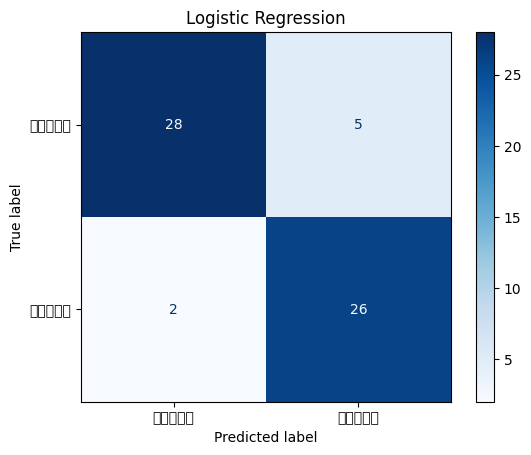


模型： Decision Tree
[[25  8]
 [ 5 23]]


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 28961 (\N{CJK UNIFIED IDEOGRAPH-7121}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24515 (\N{CJK UNIFIED IDEOGRAPH-5FC3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 33247 (\N{CJK UNIFIED IDEOGRAPH-81DF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30142 (\N{CJK UNIFIED IDEOGRAPH-75BE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30149 (\N{CJK UNIFIED IDEOGRAPH-75C5}) missing from font(s) DejaVu Sans.
  fig.canvas

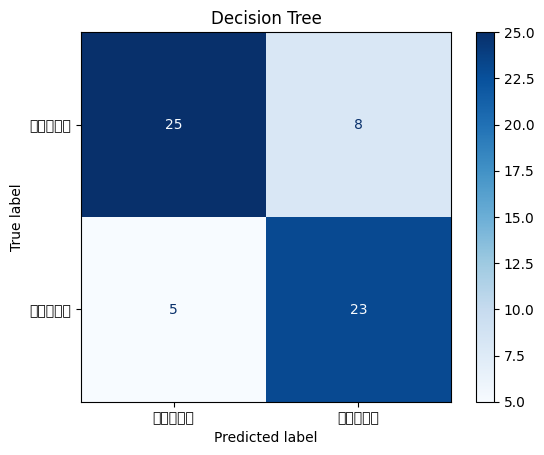


模型： Random Forest
[[27  6]
 [ 2 26]]


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 28961 (\N{CJK UNIFIED IDEOGRAPH-7121}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24515 (\N{CJK UNIFIED IDEOGRAPH-5FC3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 33247 (\N{CJK UNIFIED IDEOGRAPH-81DF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30142 (\N{CJK UNIFIED IDEOGRAPH-75BE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30149 (\N{CJK UNIFIED IDEOGRAPH-75C5}) missing from font(s) DejaVu Sans.
  fig.canvas

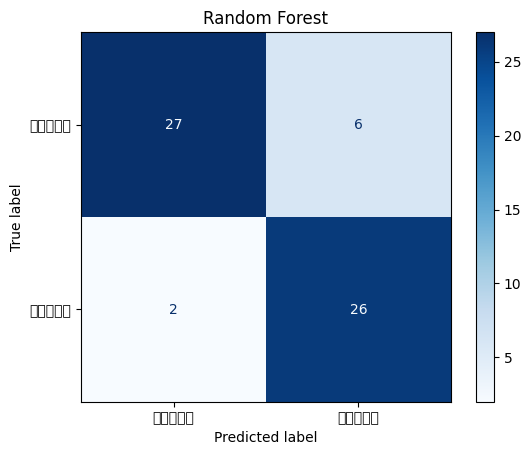

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in trained_models.items():

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred)

    print("\n模型：", name)
    print(cm)

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['無心臟疾病', '有心臟疾病']
    )

    display_cm.plot(cmap='Blues')
    plt.title(name)
    plt.show()

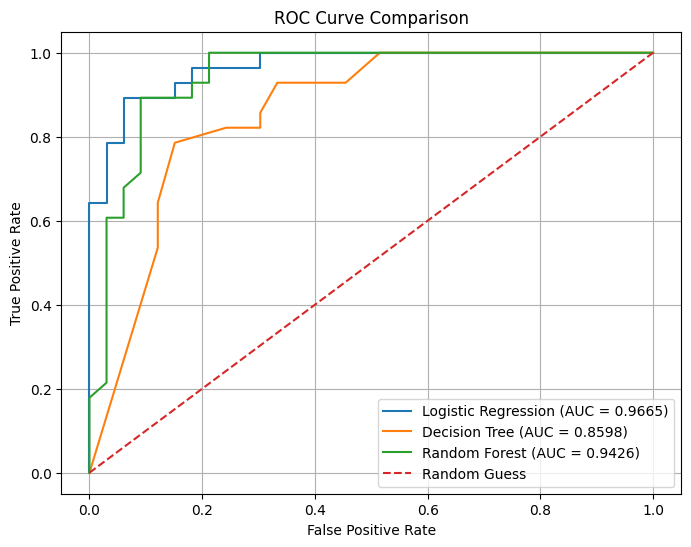

In [14]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {roc_auc:.4f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid()
plt.show()

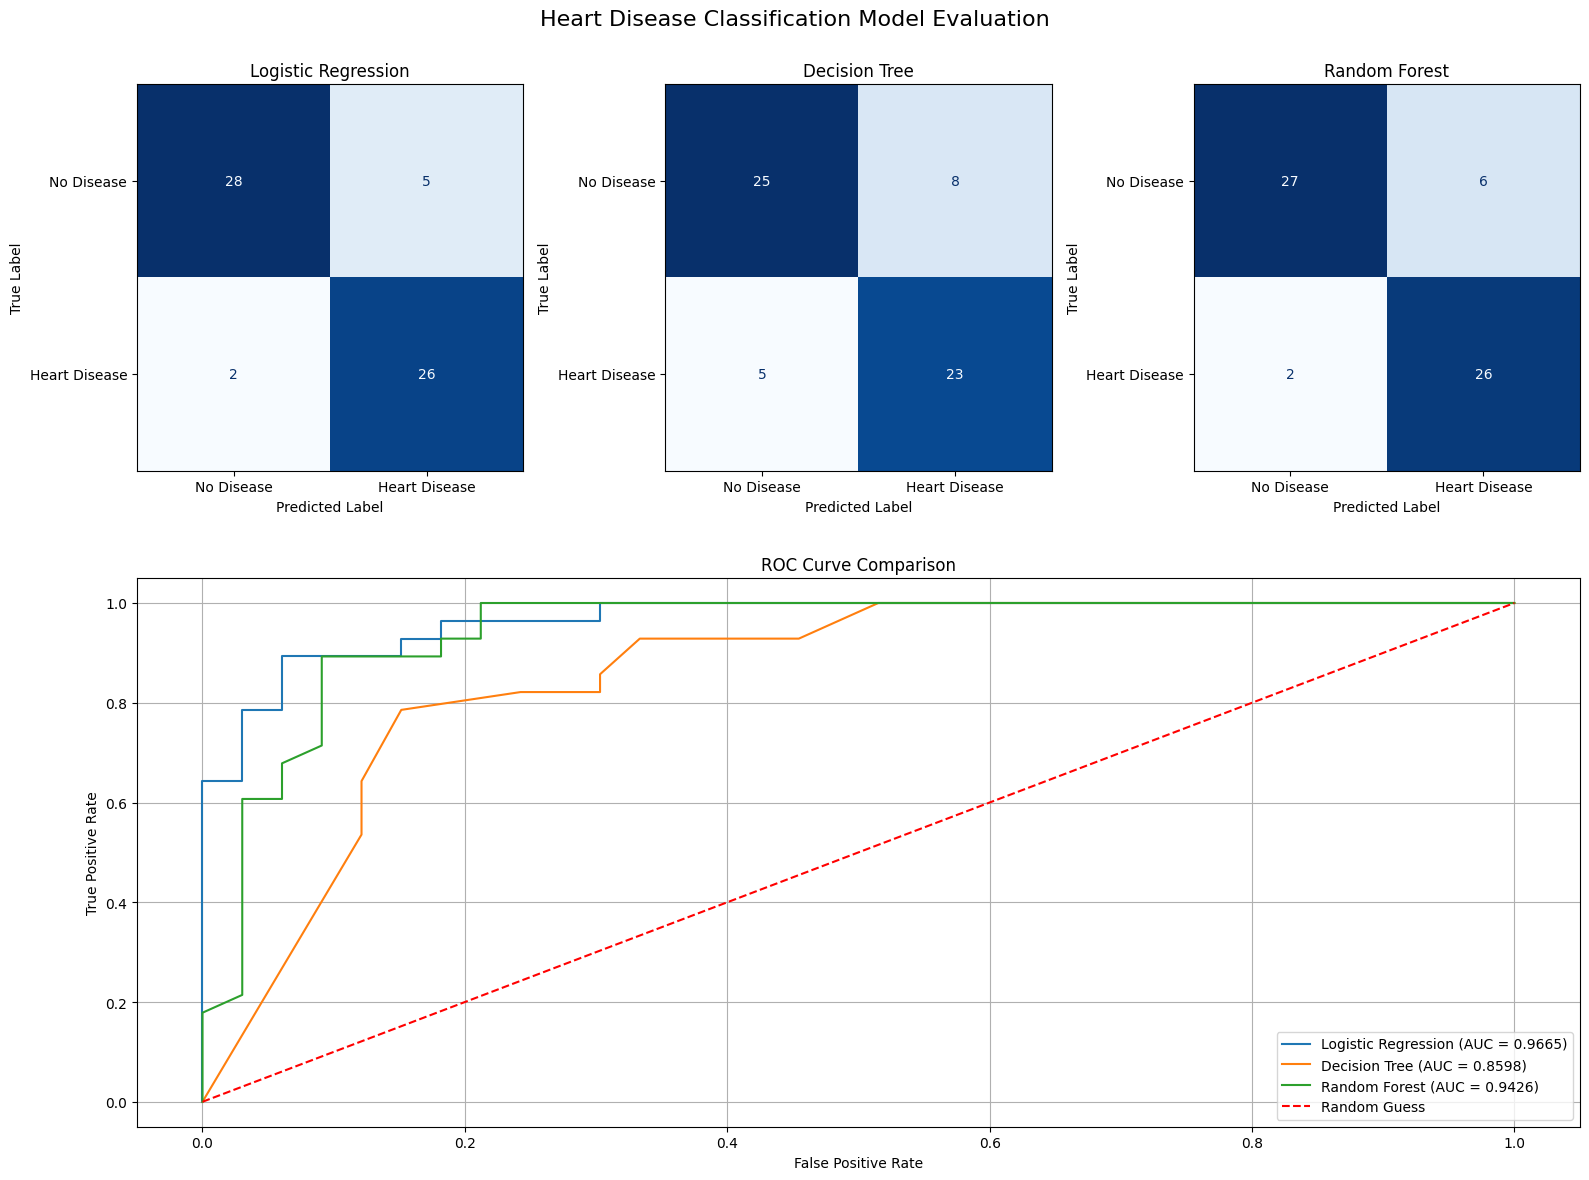

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

# 建立圖片版面：上面三張混淆矩陣，下面一張 ROC 曲線
fig = plt.figure(figsize=(16, 12))

gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.2])

# 第一部分：三種模型的混淆矩陣
for i, (name, model) in enumerate(trained_models.items()):

    ax = fig.add_subplot(gs[0, i])

    y_pred = model.predict(X_test_processed)
    cm = confusion_matrix(y_test, y_pred)

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Disease', 'Heart Disease']
    )

    display_cm.plot(
        ax=ax,
        cmap='Blues',
        values_format='d',
        colorbar=False
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

# 第二部分：ROC 曲線
ax = fig.add_subplot(gs[1, :])

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    ax.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {roc_auc:.4f})'
    )

ax.plot([0, 1], [0, 1], 'r--', label='Random Guess')

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve Comparison')
ax.legend(loc='lower right')
ax.grid()

# 整體標題
fig.suptitle(
    'Heart Disease Classification Model Evaluation',
    fontsize=16
)

plt.tight_layout()

# 儲存圖片
plt.savefig(
    'figure4-1.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()